# Electoral timing and sovereign default onset

Does annual default risk change in the expected final year of a legislative term? This notebook estimates a sequence of linear probability models, holding the country-year sample fixed as fiscal, external and institutional controls enter. Each row represents an issuer with an observed prior year outside default. The original MSc thesis and archived Stata programs are described in the [project README](../README.md).

## 1. Build the country-year panel

Run the cells in order. The downloader reuses the local cache on subsequent runs. The panel builder joins each control by country and calendar year, taking the observation from *t*−1. Missing years remain missing. Data vintages contain retrospective revisions.

In [1]:
from pathlib import Path
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

root = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "data/build_panel.py").is_file())
sys.path.insert(0, str(root))
from analysis.estimate import extended_specifications, fit, within_vif

for script in ["data/download.py", "data/build_panel.py"]:
    completed = subprocess.run([sys.executable, script], cwd=root, check=True,
                               text=True, capture_output=True)
    print(completed.stdout.strip())

panel = pd.read_csv(root / "data/processed/panel.csv")
risk = panel.loc[panel.onset.notna()].copy()
specs = extended_specifications(risk)

Matplotlib is building the font cache; this may take a moment.


defaults.xlsx: 701ccad33afd27292c418e6aa2c579f97db3016dee76da8c412966178fcb8449
etad.csv: 581b3c6fb7d9589652ce2b5e332ee42731600183f6d53fa97e14bc30ef9acbdc
restructurings.xlsx: e1dd3ced148e9365b22db2e3bf141b2de35aa39773a207581193d52486847e78
weo_oct2026.xlsx: 2aa4f70a05931197b41ed7e0202dc56eee8d816858ac14521e4f8f5dbc38696c
rule_of_law.json: 35d02f5bda5e21e6f2068ca9a8a042ff9784fb21d8bb18779fc1ed17b1a9a232
growth.json: db0eba882a9ab4c4ce5f1ac5102c9c01553634a0762cc6bc5f277b6481df9ebd
income.json: 00107c1217f46b2819956454a3b89fe23512dd6c0578f36bae5cd3cc904f8ee3
inflation.json: 470c62f4a30d7f05150daf919a3d883ca22757821f7bee39326e6db742c3f218
current_account.json: e27cadc7acee2ced1f51194961fccd6653f4faf05a3121b7741ca6d38a6d0785


5,397 matched country-years, 1,849 at risk


## 2. Compare coverage

The baseline controls for real GDP growth and log real GDP per capita. The macro specification adds gross general government debt as a share of GDP (IMF WEO), CPI inflation, and the current-account balance as a share of GDP (World Bank WDI). The balance captures external financing needs. The extended specification adds the WGI Rule of Law score, a 0–100 perception-based measure of contract enforcement, property rights and respect for legal rules. A higher score indicates stronger institutions. Using one governance dimension makes its economic meaning explicit.

The common sample requires all six controls and excludes singleton country or year groups. The first two specifications below use their broader available samples. The last row uses consecutive years for the annual HAC comparison. [World Economic Outlook](https://data.imf.org/datasets/WEO) · [World Development Indicators](https://databank.worldbank.org/source/world-development-indicators) · [Worldwide Governance Indicators](https://www.worldbank.org/en/publication/worldwide-governance-indicators)

In [2]:
coverage = []
for label, data, terms, hac in specs:
    coverage.append({"Specification": label, "Country-years": len(data),
                     "Countries": data.iso3.nunique(), "Observed years": data.year.nunique(),
                     "First year": data.year.min(), "Last year": data.year.max(),
                     "Default onsets": int(data.onset.sum())})
display(pd.DataFrame(coverage).set_index("Specification"))

,Country-years,Countries,Observed years,First year,Last year,Default onsets
Specification,,,,,,
Baseline,1693,96,62,1962,2023,209
"Macro, broad sample",814,57,33,1991,2023,95
"Baseline, common sample",747,56,24,1997,2023,89
"Macro, common sample",747,56,24,1997,2023,89
Macro and institutions,747,56,24,1997,2023,89
"Macro and institutions, annual coverage",709,56,21,2003,2023,88


## 3. Estimate the election-year association

The dependent variable equals one when the recorded default stock changes from zero to positive. The exposure equals one when the legislative term is due to expire according to the last observed vote and its recorded term length. All models include country and year fixed effects. Standard errors are clustered by country, with cluster-based degrees of freedom for the confidence intervals and *p*-values. The following cells fit the models using the same functions as the command-line replication.

In [3]:
records = []
for label, data, terms, hac in specs:
    records.extend(fit(label, data, terms, hac=hac))
estimates = pd.DataFrame(records)

cluster = estimates.loc[estimates.covariance.eq("Country cluster")]
election = cluster.loc[cluster.term.eq("term_due")].set_index("model")
scale = ["coefficient", "std_error", "lower_95", "upper_95"]
table = election[scale].mul(100).rename(columns={
    "coefficient": "Estimate (pp)", "std_error": "SE (pp)",
    "lower_95": "95% lower (pp)", "upper_95": "95% upper (pp)"})
display(table.assign(p=election.p_value, N=election.n).round(3))

,Estimate (pp),SE (pp),95% lower (pp),95% upper (pp),p,N
model,,,,,,
Baseline,-0.501,2.301,-5.070,4.067,0.828,1693
"Macro, broad sample",-1.479,3.040,-7.568,4.610,0.628,814
"Baseline, common sample",-0.872,3.265,-7.415,5.672,0.790,747
"Macro, common sample",-0.827,3.242,-7.325,5.670,0.800,747
Macro and institutions,-1.097,3.245,-7.599,5.406,0.737,747
"Macro and institutions, annual coverage",-1.081,3.388,-7.871,5.708,0.751,709


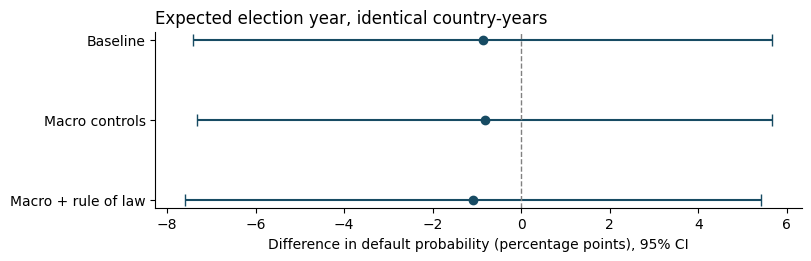

In [4]:
matched = table.loc[["Baseline, common sample", "Macro, common sample", "Macro and institutions"]]
fig, ax = plt.subplots(figsize=(8, 2.5), layout="constrained")
x = matched["Estimate (pp)"]
errors = [x - matched["95% lower (pp)"], matched["95% upper (pp)"] - x]
ax.errorbar(x, range(3), xerr=errors, fmt="o", color="#174b63", capsize=4)
ax.axvline(0, color="0.5", linestyle="--", linewidth=1)
ax.set_yticks(range(3), ["Baseline", "Macro controls", "Macro + rule of law"])
ax.invert_yaxis()
ax.set_xlabel("Difference in default probability (percentage points), 95% CI")
ax.set_title("Expected election year, identical country-years", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 4. Read the extended regression and check collinearity

Coefficients below are changes in probability per unit of the regressor. Multiply by 100 for percentage points of default risk. A one-unit change in debt, CPI inflation or the current-account balance is one percentage point in that variable. A one-unit change in governance is one WGI score point. VIFs use the residuals of each regressor after projection on both sets of fixed effects in this exact sample.

In [5]:
label = "Macro and institutions"
_, common, terms, _ = next(spec for spec in specs if spec[0] == label)
diagnostics = within_vif(common, terms)
details = cluster.loc[cluster.model.eq(label)].merge(diagnostics, on="term", validate="one_to_one")
names = {"term_due": "Expected final year", "lag_growth": "Real GDP growth (%)",
         "lag_log_income": "Log real GDP per capita", "lag_debt": "Gross government debt (% GDP)",
         "lag_inflation": "CPI inflation (%)", "lag_current_account": "Current account (% GDP)",
         "lag_rule_of_law": "Rule of Law (0–100)"}
display(details.set_index("term")[scale + ["p_value", "within_vif"]].rename(index=names).round(4))

,coefficient,std_error,lower_95,upper_95,p_value,within_vif
term,,,,,,
Expected final year,-0.0110,0.0324,-0.0760,0.0541,0.7367,1.0122
Real GDP growth (%),-0.0075,0.0030,-0.0134,-0.0016,0.0139,1.0397
Log real GDP per capita,0.1148,0.1357,-0.1571,0.3866,0.4013,1.9248
Gross government debt (% GDP),0.0032,0.0013,0.0006,0.0057,0.0160,1.7703
CPI inflation (%),0.0001,0.0037,-0.0073,0.0076,0.9697,1.0507
Current account (% GDP),-0.0046,0.0018,-0.0082,-0.0010,0.0137,1.1158
Rule of Law (0–100),-0.0112,0.0036,-0.0184,-0.0041,0.0027,1.0926


## 5. Check serial and cross-country dependence

WGI observations are intermittent early in the panel. The Driscoll–Kraay check uses the consecutive 2003–2023 period, a Bartlett kernel and three annual lags. Both rows below use exactly the same observations and fixed effects. With 21 annual periods, HAC inference is a sensitivity check.

In [6]:
annual = estimates.loc[estimates.model.eq("Macro and institutions, annual coverage")
                       & estimates.term.eq("term_due")].set_index("covariance")
display(annual[scale].mul(100).add_suffix(" (pp)").assign(p=annual.p_value, N=annual.n).round(3))

,coefficient (pp),std_error (pp),lower_95 (pp),upper_95 (pp),p,N
covariance,,,,,,
Country cluster,-1.081,3.388,-7.871,5.708,0.751,709
Driscoll-Kraay (3 lags),-1.081,1.827,-4.893,2.731,0.561,709


## Interpretation

On identical country-years, the estimated election coefficient is −0.87 percentage points with the original controls and −1.10 with all six. Its country-clustered 95% interval in the extended model spans −7.60 to +5.41 points. The largest within-sample VIF is 1.92. Limited precision remains even though collinearity among the regressors is low.

Higher lagged debt and weaker rule of law are associated with higher annual default risk in this sample. The controls and fixed effects cannot establish causality. Fiscal stress can affect both the timing of elections and debt outcomes, and annual observations cannot determine which event occurred first within an election year.